# EM Algorithm for a Gaussian Mixture Model (GMM)
**Dataset:** Old Faithful Geyser (Kaggle: *faithful.csv*) - column `waiting` = minutes between eruptions.

The data has two hidden groups (short wait / long wait). We do not know which eruption belongs to which group, so we use EM to find them.

Same idea as the two-coin problem:

| Coin example | GMM |
|---|---|
| Coin A / Coin B | Gaussian 1 / Gaussian 2 |
| theta (bias) | mean `mu`, variance `var` |
| mixing prob pi | mixing prob pi |
| P(Z_A), P(Z_B) | responsibilities r1, r2 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 1: Load the Kaggle dataset
Download `faithful.csv` from Kaggle (Old Faithful Geyser data) and upload it in Colab (left panel > Files > Upload).

In [2]:
df = pd.read_csv("faithful.csv")

print("Shape:", df.shape)
df.head()

Shape: (272, 3)


,Unnamed: 0,eruptions,waiting
0,1,3.600,79
1,2,1.800,54
2,3,3.333,74
3,4,2.283,62
4,5,4.533,85


## Step 2: Take the column we will model
We use only `waiting` (1-D data), so every formula stays simple.

In [3]:
x = df["waiting"].values.astype(float)
n = len(x)

print("Number of data points:", n)
print("Mean:", round(x.mean(), 2))
print("Std :", round(x.std(), 2))
print("Min :", x.min(), " Max:", x.max())

Number of data points: 272
Mean: 70.9
Std : 13.57
Min : 43.0  Max: 96.0


In [ ]:
plt.hist(x, bins=25, color="lightblue", edgecolor="black")
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Count")
plt.title("Waiting time - two humps, so two hidden Gaussians")
plt.show()

## Step 3: Initial guess (like theta_A = 0.60, theta_B = 0.50 in the class example)
For 2 Gaussians we need: mean, variance and mixing probability of each.

In [4]:
mu1, mu2 = 50.0, 80.0          # initial means (guess from the histogram)
var1 = var2 = np.var(x)        # start both variances equal to the data variance
pi1, pi2 = 0.5, 0.5            # equal mixing probability

print("mu :", mu1, mu2)
print("var:", round(var1, 2), round(var2, 2))
print("pi :", pi1, pi2)

mu : 50.0 80.0
var: 184.14 184.14
pi : 0.5 0.5


## Step 4: Gaussian formula (replaces the Binomial likelihood)

$$N(x\mid\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}\;e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

In [5]:
def gaussian(x, mu, var):
    return (1 / np.sqrt(2 * np.pi * var)) * np.exp(-(x - mu) ** 2 / (2 * var))

## Step 5: E-step - "which Gaussian probably made each point?"

$$r_{i1}=\frac{\pi_1\,N(x_i\mid\mu_1,\sigma_1^2)}{\pi_1\,N(x_i\mid\mu_1,\sigma_1^2)+\pi_2\,N(x_i\mid\mu_2,\sigma_2^2)},\qquad r_{i2}=1-r_{i1}$$

This is exactly `P(Z_A) = 0.036 / (0.036 + 0.009)` from the class example.

In [6]:
# Likelihood of every point under each Gaussian
L1 = pi1 * gaussian(x, mu1, var1)
L2 = pi2 * gaussian(x, mu2, var2)

# Responsibilities
r1 = L1 / (L1 + L2)
r2 = 1 - r1

print("Point | x  | Gaussian 1 | Gaussian 2")
for i in range(5):
    print(f"{i+1:<5} | {x[i]:<2.0f} | {r1[i]:.4f}     | {r2[i]:.4f}")

Point | x  | Gaussian 1 | Gaussian 2
1     | 79 | 0.0927     | 0.9073
2     | 54 | 0.8572     | 0.1428
3     | 74 | 0.1875     | 0.8125
4     | 62 | 0.6198     | 0.3802
5     | 85 | 0.0370     | 0.9630


## Step 6: M-step - "update the parameters using those weights"

$$N_k=\sum_i r_{ik},\quad \mu_k=\frac{\sum_i r_{ik}x_i}{N_k},\quad \sigma_k^2=\frac{\sum_i r_{ik}(x_i-\mu_k)^2}{N_k},\quad \pi_k=\frac{N_k}{n}$$

This is the same as `theta_A = weighted heads / (weighted heads + weighted tails)`.

In [7]:
N1 = np.sum(r1)
N2 = np.sum(r2)

mu1 = np.sum(r1 * x) / N1
mu2 = np.sum(r2 * x) / N2

var1 = np.sum(r1 * (x - mu1) ** 2) / N1
var2 = np.sum(r2 * (x - mu2) ** 2) / N2

pi1 = N1 / n
pi2 = N2 / n

print("After iteration 1")
print(f"Gaussian 1: mu={mu1:.3f}, var={var1:.3f}, pi={pi1:.4f}")
print(f"Gaussian 2: mu={mu2:.3f}, var={var2:.3f}, pi={pi2:.4f}")

After iteration 1
Gaussian 1: mu=57.753, var=103.774, pi=0.3594
Gaussian 2: mu=78.271, var=77.946, pi=0.6406


## Step 7: Repeat E and M until it stops changing
We also track the **log-likelihood** - it must never go down. We stop when it changes by less than the tolerance.

$$\log L=\sum_i \log\big(\pi_1N(x_i\mid\mu_1,\sigma_1^2)+\pi_2N(x_i\mid\mu_2,\sigma_2^2)\big)$$

In [8]:
# Start again from the same initial guess
mu1, mu2 = 50.0, 80.0
var1 = var2 = np.var(x)
pi1, pi2 = 0.5, 0.5

max_iter = 100
tolerance = 0.000001
loglik_history = []
old_loglik = -np.inf

for it in range(max_iter):

    # E-step
    L1 = pi1 * gaussian(x, mu1, var1)
    L2 = pi2 * gaussian(x, mu2, var2)
    r1 = L1 / (L1 + L2)
    r2 = 1 - r1

    # Log-likelihood with the current parameters
    loglik = np.sum(np.log(L1 + L2))
    loglik_history.append(loglik)

    # M-step
    N1 = np.sum(r1)
    N2 = np.sum(r2)

    mu1 = np.sum(r1 * x) / N1
    mu2 = np.sum(r2 * x) / N2

    var1 = np.sum(r1 * (x - mu1) ** 2) / N1
    var2 = np.sum(r2 * (x - mu2) ** 2) / N2

    pi1 = N1 / n
    pi2 = N2 / n

    print(f"Iteration {it+1}: mu1={mu1:.3f}, mu2={mu2:.3f}, pi1={pi1:.4f}, logL={loglik:.4f}")

    # Check convergence
    if abs(loglik - old_loglik) < tolerance:
        print("Converged!")
        break
    old_loglik = loglik

Iteration 1: mu1=57.753, mu2=78.271, pi1=0.3594, logL=-1135.3677
Iteration 2: mu1=56.381, mu2=79.299, pi1=0.3666, logL=-1069.0314
Iteration 3: mu1=55.460, mu2=79.996, pi1=0.3708, logL=-1051.0236
Iteration 4: mu1=55.036, mu2=80.213, pi1=0.3700, logL=-1037.5889
Iteration 5: mu1=54.858, mu2=80.213, pi1=0.3674, logL=-1034.4594
Iteration 6: mu1=54.767, mu2=80.179, pi1=0.3653, logL=-1034.1296
Iteration 7: mu1=54.713, mu2=80.150, pi1=0.3638, logL=-1034.0542
Iteration 8: mu1=54.679, mu2=80.130, pi1=0.3628, logL=-1034.0242
Iteration 9: mu1=54.657, mu2=80.117, pi1=0.3621, logL=-1034.0114
Iteration 10: mu1=54.642, mu2=80.108, pi1=0.3617, logL=-1034.0059
Iteration 11: mu1=54.633, mu2=80.102, pi1=0.3614, logL=-1034.0035
Iteration 12: mu1=54.627, mu2=80.099, pi1=0.3612, logL=-1034.0025
Iteration 13: mu1=54.623, mu2=80.096, pi1=0.3611, logL=-1034.0021
Iteration 14: mu1=54.620, mu2=80.094, pi1=0.3610, logL=-1034.0019
Iteration 15: mu1=54.618, mu2=80.093, pi1=0.3610, logL=-1034.0018
Iteration 16: mu1=5

## Step 8: Final results

In [9]:
print("FINAL RESULTS\n")
print(f"Gaussian 1 (short wait): mean={mu1:.3f}, variance={var1:.3f}, std={np.sqrt(var1):.3f}, mixing prob={pi1:.4f}")
print(f"Gaussian 2 (long wait) : mean={mu2:.3f}, variance={var2:.3f}, std={np.sqrt(var2):.3f}, mixing prob={pi2:.4f}")
print("\nIterations used:", len(loglik_history))
print("Final log-likelihood:", round(loglik_history[-1], 4))

FINAL RESULTS

Gaussian 1 (short wait): mean=54.615, variance=34.474, std=5.871, mixing prob=0.3609
Gaussian 2 (long wait) : mean=80.091, variance=34.428, std=5.868, mixing prob=0.6391

Iterations used: 21
Final log-likelihood: -1034.0018


## Step 9: Log-likelihood should only go up

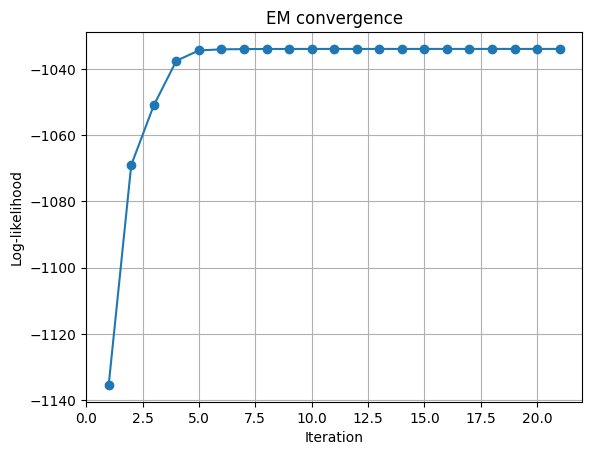

Always increasing: True


In [10]:
plt.plot(range(1, len(loglik_history) + 1), loglik_history, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM convergence")
plt.grid(True)
plt.show()

# Check: no decrease at any step
print("Always increasing:", all(np.diff(loglik_history) >= -1e-9))

## Step 10: Fitted Gaussians on top of the data

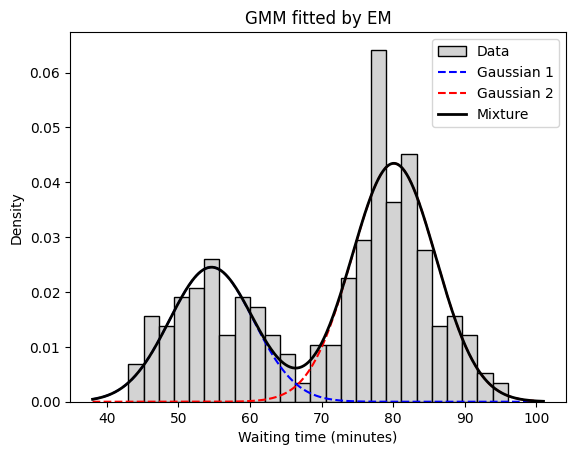

In [11]:
xs = np.linspace(x.min() - 5, x.max() + 5, 400)
g1 = pi1 * gaussian(xs, mu1, var1)
g2 = pi2 * gaussian(xs, mu2, var2)

plt.hist(x, bins=25, density=True, color="lightgrey", edgecolor="black", label="Data")
plt.plot(xs, g1, "b--", label="Gaussian 1")
plt.plot(xs, g2, "r--", label="Gaussian 2")
plt.plot(xs, g1 + g2, "k", linewidth=2, label="Mixture")
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Density")
plt.title("GMM fitted by EM")
plt.legend()
plt.show()

## Step 11: Hard cluster labels
Each point goes to the Gaussian with the larger responsibility.

## Step 12 (check): compare with scikit-learn
Our from-scratch answer should match the library.

In [13]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=2, random_state=0).fit(x.reshape(-1, 1))
order = np.argsort(gm.means_.ravel())

print("sklearn means    :", gm.means_.ravel()[order].round(3))
print("sklearn variances:", gm.covariances_.ravel()[order].round(3))
print("sklearn weights  :", gm.weights_[order].round(4))

print("\nOur means        :", np.round([mu1, mu2], 3))
print("Our variances    :", np.round([var1, var2], 3))
print("Our weights      :", np.round([pi1, pi2], 4))

sklearn means    : [54.7   80.145]
sklearn variances: [35.318 33.79 ]
sklearn weights  : [0.3635 0.6365]

Our means        : [54.615 80.091]
Our variances    : [34.474 34.428]
Our weights      : [0.3609 0.6391]
